In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

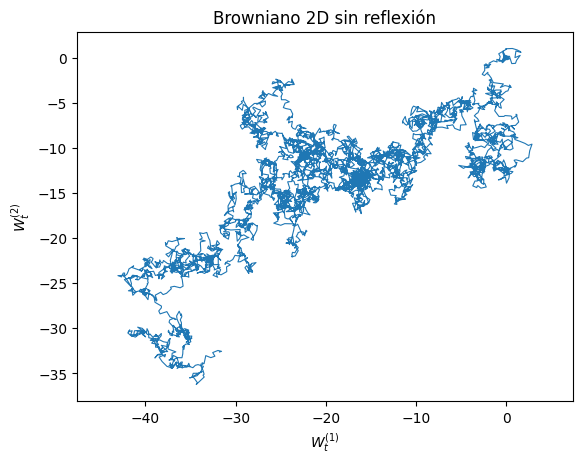

In [ ]:
#Browniano en 2 dimensiones
N = 5000
dt = 0.1
T = dt * N
t = np.linspace(0, T, N+1)

rng2 = np.random.default_rng(789) #semilla a utilizar
Z = rng2.normal(0, 1, size = (2, N)) # definimos una normal 2D
dW = np.sqrt(dt) * Z # incremento browniano

W = np.cumsum(dW, axis=1)              # forma (2, N)
W = np.insert(W, 0, [0, 0], axis=1)    # forma (2, N+1), con columna inicial = origen

plt.plot(W[0,:], W[1,:], lw=0.8)
plt.xlabel("$W^{(1)}_t$")
plt.ylabel("$W^{(2)}_t$")
plt.title("Browniano 2D sin reflexión")
plt.axis("equal")   # importante: misma escala en ambos ejes
plt.show()


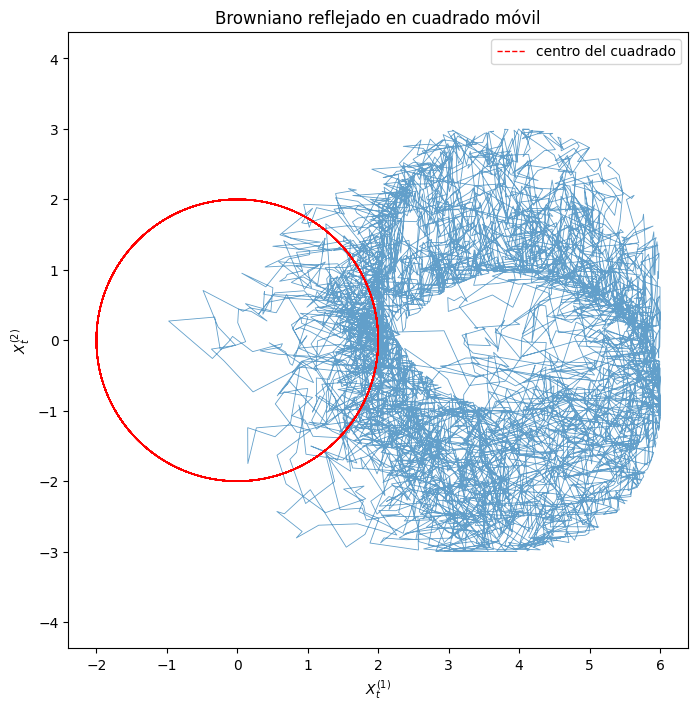

In [ ]:
from re import X
A = 2.0
omega = 0.3
mu = 0.001

#trayectoria del centro del cuadrado
c1 = A * np.cos(omega * t)
c2 = A * np.sin(omega * t)

#calculamos la proyección para cada t
def proy_cuadrado_movil(x, L, centro):
    x1_proy = np.clip(x[0], centro[0] - L, centro[0] + L)
    x2_proy = np.clip(x[1], centro[1] - h, centro[1] + h)
    return np.array([x1_proy, x2_proy])

h = 1.0
L = 4
X_movil = np.zeros((2, N+1))
X_movil[:, 0] = np.array([c1[0], c2[0]])   # partimos en el centro inicial del cuadrado

def drift(X_movil):
  return np.array([1, 0])

def diffusion(X_movil):
  return

for n in range(N):
    centro_actual = np.array([c1[n], c2[n]])
    paso_libre = X_movil[:, n] + drift(X_movil) * dt + dW[:, n]
    X_movil[:, n+1] = proy_cuadrado_movil(paso_libre, L, centro_actual)

plt.figure(figsize=(8,8))
plt.plot(X_movil[0,:], X_movil[1,:], lw=0.6, alpha=0.7)
plt.plot(c1, c2, color="red", linestyle="--", lw=1, label="centro del cuadrado")
plt.xlabel("$X^{(1)}_t$")
plt.ylabel("$X^{(2)}_t$")
plt.title("Browniano reflejado en cuadrado móvil")
plt.axis("equal")
plt.legend()
plt.savefig("trayectoria final.png", dpi= 300)
plt.show()


tau = 86.43


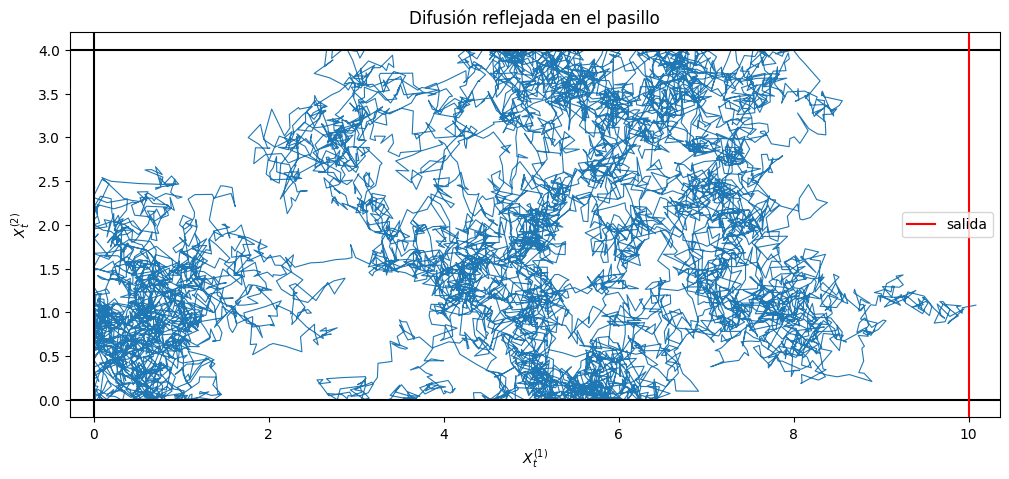

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Parámetros ----------
ell = 10.0    # largo del pasillo
w   = 4.0     # ancho
bx, by  = 0.2, 0.0     # deriva en x
dt  = 0.01
T   = 1000.0

N = int(T / dt)                 # FIX 1: definir N ANTES de usarlo
X = np.zeros((2, N + 1))
X[:, 0] = np.array([0.0, w / 2])   # pared izquierda, centrado

# ---------- Browniano 2D ----------
rng2 = np.random.default_rng(789)
Z  = rng2.normal(0, 1, size=(2, N))
dW = np.sqrt(dt) * Z

# ---------- Proyección al pasillo ----------
def proy_pasillo(y, ell, w):
    x_proy = np.maximum(y[0], 0)   # solo pared izquierda en x
    y_proy = np.clip(y[1], 0, w)   # ambas paredes en y
    return np.array([x_proy, y_proy])

# ---------- Coeficientes ----------
def b_func(x):
    return np.array([bx, by])

def sigma_func(x):
    return 1.0

# ---------- Euler–Maruyama proyectado ----------
tau, n_salida = None, N          # FIX 2: valores por defecto si no sale

for n in range(N):
    b_n     = b_func(X[:, n])
    sigma_n = sigma_func(X[:, n])
    paso_libre = X[:, n] + b_n * dt + sigma_n * dW[:, n]
    X[:, n + 1] = proy_pasillo(paso_libre, ell, w)
    if X[0, n + 1] >= ell:       # ¿cruzó la salida?
        n_salida = n + 1
        tau = n_salida * dt
        break

if tau is not None:
    print(f"tau = {tau:.2f}")
else:
    print(f"No salió en T = {T} (aumenta T o revisa la deriva)")

# ---------- Gráfico ----------
plt.figure(figsize=(12, 5))
plt.plot(X[0, :n_salida + 1], X[1, :n_salida + 1], lw=0.8)
plt.axhline(0, color="black")
plt.axhline(w, color="black")
plt.axvline(0, color="black")
plt.axvline(ell, color="red", label="salida")
plt.axis("equal")
plt.xlabel("$X^{(1)}_t$")
plt.ylabel("$X^{(2)}_t$")
plt.title("Difusión reflejada en el pasillo")
plt.legend()
plt.show()

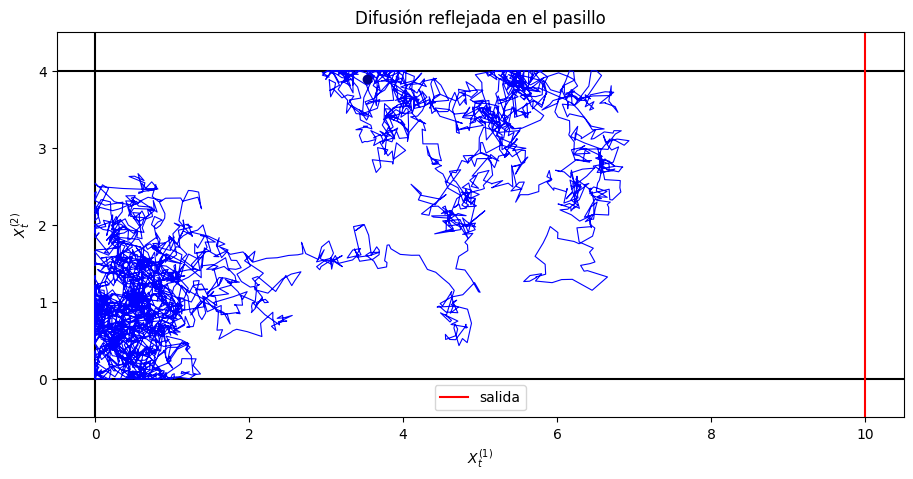

In [ ]:
salto = 10                          # animar 1 de cada 20 pasos
frames_idx = range(0, n_salida+1, salto)   # los índices que sí se dibujan

fig, ax = plt.subplots(figsize=(12, 5))
ax.axhline(0, color="black")
ax.axhline(w, color="black")
ax.axvline(0, color="black")
ax.axvline(ell, color="red", label="salida")
ax.set_xlim(-0.5, ell + 0.5)
ax.set_ylim(-0.5, w + 0.5)
ax.set_aspect("equal")
ax.set_xlabel("$X^{(1)}_t$")
ax.set_ylabel("$X^{(2)}_t$")
ax.set_title("Difusión reflejada en el pasillo")
ax.legend()


linea, = ax.plot([], [], lw=0.8, color="blue")      # la estela
punto, = ax.plot([], [], "o", color="darkblue")     # la posición actual


def update(i):
    linea.set_data(X[0, :i+1], X[1, :i+1])   # estela desde el inicio hasta i
    punto.set_data([X[0, i]], [X[1, i]])      # punto en la posición i
    return linea, punto


stride = 30                                      # desplazamiento/cuadro: 0.35·√0.3 ≈ 0.19 ≪ w
frames = N // stride                             # ≈ 3333 cuadros
anim   = FuncAnimation(fig, update, frames=frames, interval=40, blit=True)
anim.save("difusion_L.gif", fps=25, dpi=110)     # v = 30·0.01·25 = 7.5 unid/s, suave

In [ ]:
def simular_tau(sigma, bx, semilla):
    X = np.zeros((2, N+1))
    X[:, 0] = np.array([0.0, w/2])

    rng = np.random.default_rng(semilla)
    Z = rng.normal(0, 1, size=(2, N))
    dW = np.sqrt(dt) * Z

    b = np.array([bx, 0.0])

    tau = None
    for n in range(N):
        paso_libre = X[:, n] + b * dt + sigma * dW[:, n]
        X[:, n+1] = proy_pasillo(paso_libre, ell, w)
        if X[0, n+1] >= ell:
            tau = (n + 1) * dt
            break

    return tau

print(simular_tau(sigma=0.01, bx=0.1, semilla=789))

sigma_fijo = 0.5
M = 100

taus = []
for m in range(M):
    tau = simular_tau(sigma=sigma_fijo, bx=0.1, semilla=m)
    taus.append(tau)

taus_validos = [t for t in taus if t is not None]
promedio = np.mean(taus_validos)

print(f"sigma = {sigma_fijo}, E[tau] = {promedio:.2f}")


101.2
sigma = 0.5, E[tau] = 91.16


sigma = 0.01, E[tau] = 100.01
sigma = 0.1, E[tau] = 100.05
sigma = 0.3, E[tau] = 97.98
sigma = 0.5, E[tau] = 91.16
sigma = 1.0, E[tau] = 60.56
sigma = 1.5, E[tau] = 36.13
sigma = 2, E[tau] = 20.72
sigma = 2.5, E[tau] = 15.26
sigma = 3, E[tau] = 11.52


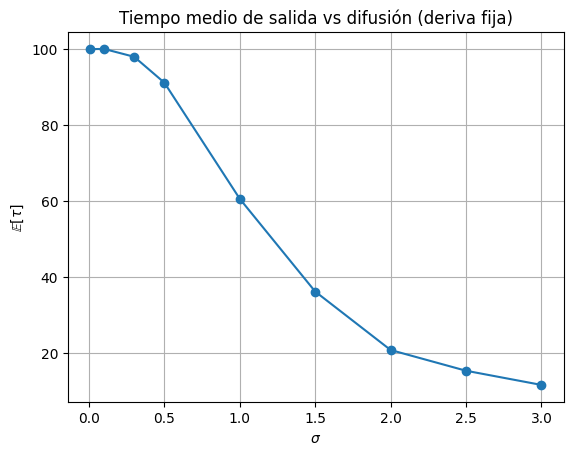

In [ ]:
sigmas = [0.01, 0.1, 0.3, 0.5, 1.0, 1.5, 2, 2.5, 3]
bx_fijo = 0.1
M = 100

promedios = []
for sigma_actual in sigmas:
    taus = []
    for m in range(M):
        tau = simular_tau(sigma=sigma_actual, bx=bx_fijo, semilla=m)
        taus.append(tau)
    taus_validos = [t for t in taus if t is not None]
    promedio = np.mean(taus_validos)
    promedios.append(promedio)
    print(f"sigma = {sigma_actual}, E[tau] = {promedio:.2f}")

plt.plot(sigmas, promedios, marker="o")
plt.xlabel(r"$\sigma$")
plt.ylabel(r"$\mathbb{E}[\tau]$")
plt.title("Tiempo medio de salida vs difusión (deriva fija)")
plt.grid(True)
plt.savefig("tau_vs_deriva.png", dpi = 300)
plt.show()

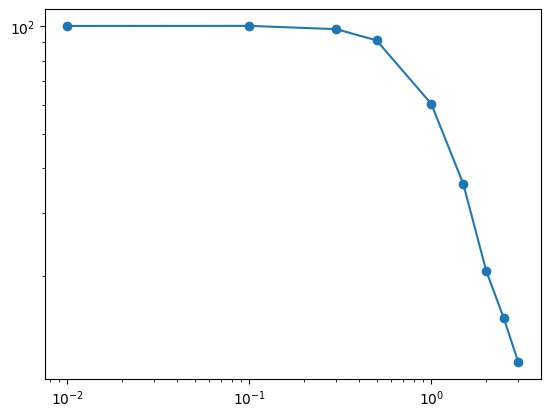

In [ ]:
plt.plot(sigmas, promedios, marker="o")
plt.xscale("log")
plt.yscale("log")

In [ ]:
bxs = [0.05, 0.1, 0.2, 0.4, 0.8]

sigma_fijo = 0.3
M = 100

for bx_actual in bxs:
    taus = []
    for m in range(M):
        tau = simular_tau(sigma=sigma_fijo, bx=bx_actual, semilla=m)
        taus.append(tau)
    taus_validos = [t for t in taus if t is not None]
    promedio = np.mean(taus_validos)
    print(f"bx = {bx_actual}, E[tau] = {promedio:.2f}")   # ← el formato que pediste

bx = 0.05, E[tau] = 179.69
bx = 0.1, E[tau] = 97.98
bx = 0.2, E[tau] = 49.24
bx = 0.4, E[tau] = 24.42
bx = 0.8, E[tau] = 12.33


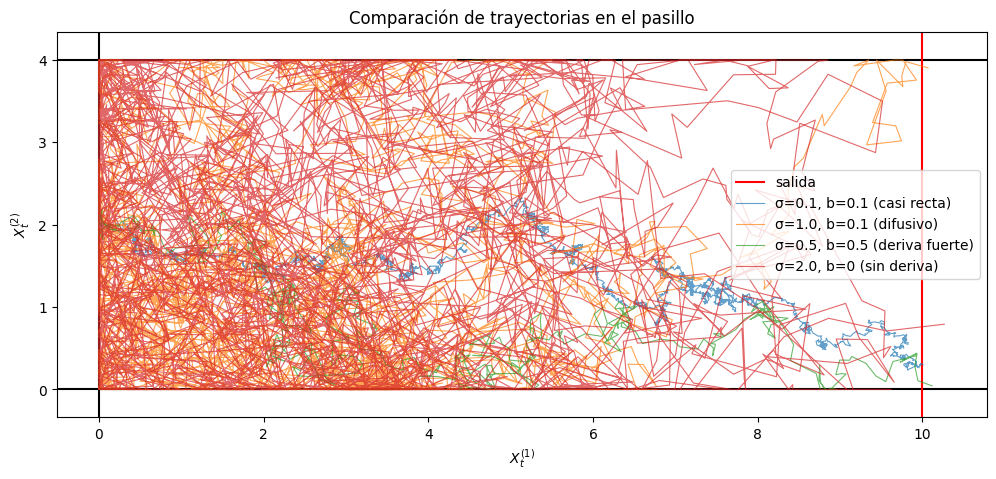

In [ ]:
def simular_tray(sigma, bx, semilla):
    X = np.zeros((2, N+1))
    X[:, 0] = np.array([0.0, w/2])

    rng = np.random.default_rng(semilla)
    Z = rng.normal(0, 1, size=(2, N))
    dW = np.sqrt(dt) * Z

    b = np.array([bx, 0.0])

    n_salida = N
    for n in range(N):
        paso_libre = X[:, n] + b * dt + sigma * dW[:, n]
        X[:, n+1] = proy_pasillo(paso_libre, ell, w)
        if X[0, n+1] >= ell:
            n_salida = n + 1
            break

    return X[:, :n_salida+1]

casos = [
    {"sigma": 0.1, "bx": 0.1, "etiqueta": "σ=0.1, b=0.1 (casi recta)"},
    {"sigma": 1.0, "bx": 0.1, "etiqueta": "σ=1.0, b=0.1 (difusivo)"},
    {"sigma": 0.5, "bx": 0.5, "etiqueta": "σ=0.5, b=0.5 (deriva fuerte)"},
    {"sigma": 2.0, "bx": 0.0, "etiqueta": "σ=2.0, b=0 (sin deriva)"},
]

plt.figure(figsize=(12, 5))

# escenario del pasillo (una vez)
plt.axhline(0, color="black")
plt.axhline(w, color="black")
plt.axvline(0, color="black")
plt.axvline(ell, color="red", label="salida")

# una trayectoria por caso
for caso in casos:
    Xtray = simular_tray(caso["sigma"], caso["bx"], semilla=42)
    plt.plot(Xtray[0], Xtray[1], lw=0.8, alpha=0.7, label=caso["etiqueta"])

plt.axis("equal")
plt.xlabel("$X^{(1)}_t$")
plt.ylabel("$X^{(2)}_t$")
plt.title("Comparación de trayectorias en el pasillo")
plt.legend()
plt.savefig("comparación_sigma_pasillo.png", dpi = 300)
plt.show()

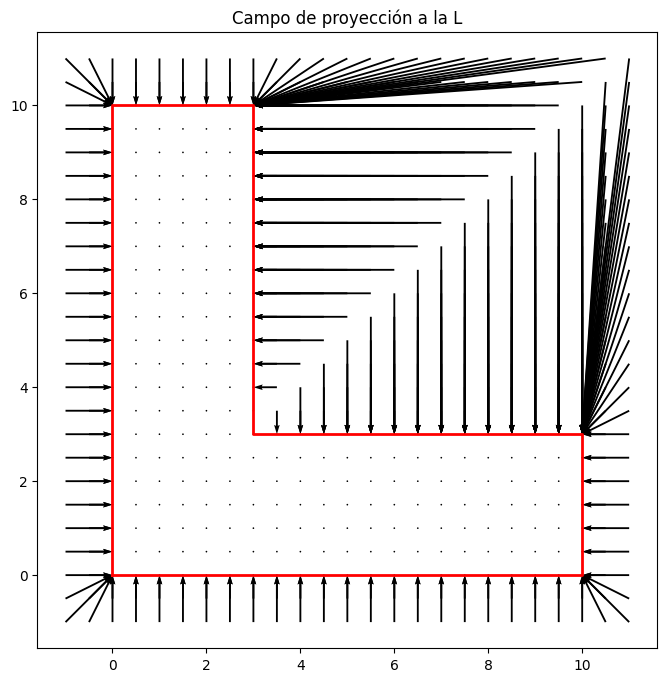

In [ ]:
def clip_box(y, x0, x1, y0, y1):
    x_proy = np.clip(y[0], x0, x1)
    y_proy = np.clip(y[1], y0, y1)
    return np.array([x_proy, y_proy])

def proy_L(y, ell1, ell2, w):
    p1 = clip_box(y, 0, ell1, 0, w)      # brazo horizontal
    p2 = clip_box(y, 0, w, 0, ell2)      # brazo vertical

    d1 = np.linalg.norm(y - p1)          # distancia a la proyección en R1
    d2 = np.linalg.norm(y - p2)          # distancia a la proyección en R2

    if d1 <= d2:                         # convención de empate: si igual, elige horizontal
        return p1
    else:
        return p2
ell1, ell2, w = 10, 10, 3

# malla de puntos
xs = np.linspace(-1, ell1+1, 25)
ys = np.linspace(-1, ell2+1, 25)
GX, GY = np.meshgrid(xs, ys)

# proyectar cada punto y guardar el vector de desplazamiento
U = np.zeros_like(GX)
V = np.zeros_like(GY)
for i in range(GX.shape[0]):
    for j in range(GX.shape[1]):
        y = np.array([GX[i,j], GY[i,j]])
        p = proy_L(y, ell1, ell2, w)
        U[i,j] = p[0] - y[0]      # cuánto se movió en x
        V[i,j] = p[1] - y[1]      # cuánto se movió en y

plt.figure(figsize=(8,8))
plt.quiver(GX, GY, U, V, angles="xy", scale_units="xy", scale=1, width=0.003)
# contorno de la L para referencia
plt.plot([0,ell1,ell1,w,w,0,0], [0,0,w,w,ell2,ell2,0], "r-", lw=2)
plt.axis("equal")
plt.title("Campo de proyección a la L")
plt.show()

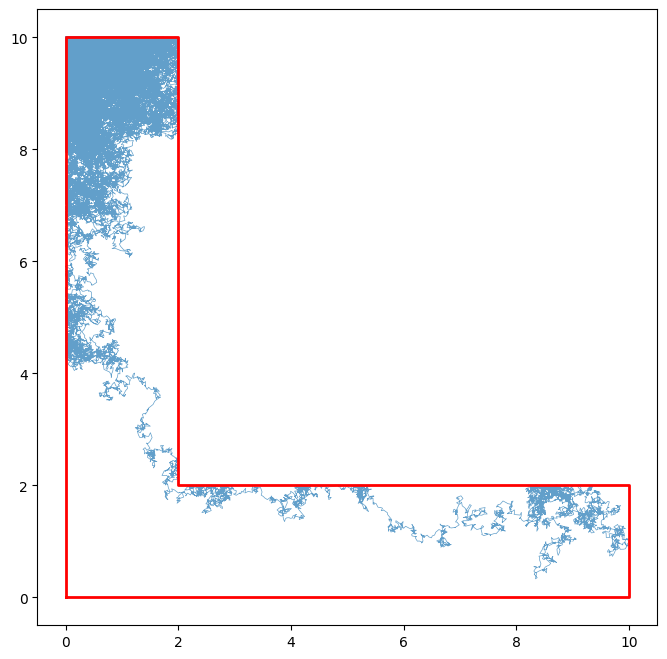

In [ ]:
#simulación de L
ell1  = 10.0
ell2  = 10.0
w     = 2.0
bx, by    = -0.1, 0.1
dt    = 0.01
T = 1000
sigma = 0.35
N     = int(T / dt)

X = np.zeros((2, N+1))
X[:, 0] = np.array([ell1 -1 , w/2])
  # pared izquierda, centrado en el ancho

#Browniano en 2 dimensiones
T = dt * N
t = np.linspace(0, T, N+1)

rng2 = np.random.default_rng(800) #semilla a utilizar
Z = rng2.normal(0, 1, size = (2, N)) # definimos una normal 2D
dW = np.sqrt(dt) * Z # incremento browniano

W = np.cumsum(dW, axis=1)              # forma (2, N)
W = np.insert(W, 0, [0, 0], axis=1)    # forma (2, N+1), con columna inicial = origen


# Proyección dentro del pasillo

def clip_box(y, x0, x1, y0, y1):
    x_proy = np.clip(y[0], x0, x1)
    y_proy = np.clip(y[1], y0, y1)
    return np.array([x_proy, y_proy])

def proy_L(y, ell1, ell2, w):
    p1 = clip_box(y, 0, ell1, 0, w)      # brazo horizontal (cerrado, como antes)
    p2 = clip_box(y, 0, w, 0, ell2)      # brazo vertical CERRADO (tope en ell2)
    d1 = np.linalg.norm(y - p1)
    d2 = np.linalg.norm(y - p2)
    return p1 if d1 <= d2 else p2


# Euler-Maruyama

def b_func(x):
    return np.array([bx, by])

def sigma_func(x):
    return sigma

tau = None # tiempo de salida

for n in range(N):
    b_n = b_func(X[:, n])
    sigma_n = sigma_func(X[:, n])
    paso_libre = X[:, n] + b_n * dt + sigma_n * dW[:, n]
    X[:, n+1] = proy_L(paso_libre, ell1, ell2, w)


plt.figure(figsize=(8, 8))
plt.plot(X[0, :], X[1, :], lw=0.5, alpha=0.7, label="trayectoria")   # <- la línea que faltaba
plt.plot([0,ell1,ell1,w,w,0,0], [0,0,w,w,ell2,ell2,0], "r-", lw=2, label="borde L")

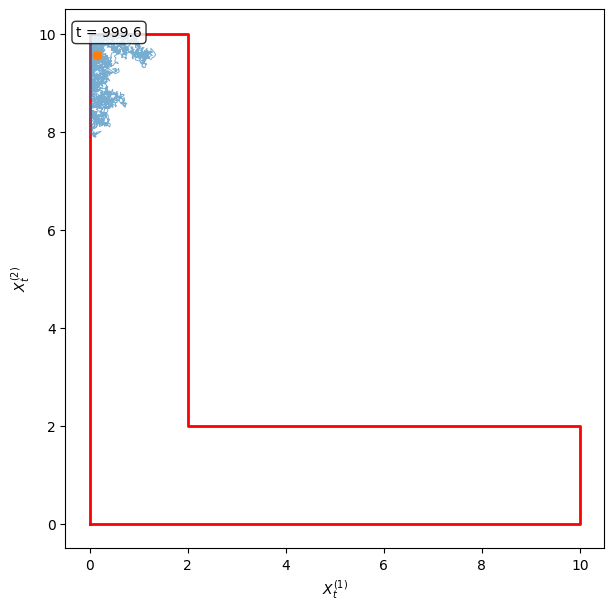

In [ ]:
stride  = 250                       # pasos de simulación por cuadro
frames  = N // stride               # ≈ 400 cuadros
trail   = 4000                      # largo de la estela (en pasos), ~40 unid. de tiempo

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0,ell1,ell1,w,w,0,0], [0,0,w,w,ell2,ell2,0], "r-", lw=2)
ax.set_xlim(-0.5, ell1+0.5); ax.set_ylim(-0.5, ell2+0.5)
ax.set_aspect("equal")
ax.set_xlabel("$X^{(1)}_t$"); ax.set_ylabel("$X^{(2)}_t$")

linea,  = ax.plot([], [], lw=0.7, alpha=0.6, color="C0")     # estela
punto,  = ax.plot([], [], "o", ms=6, color="C1")             # posición actual
reloj   = ax.text(0.02, 0.97, "", transform=ax.transAxes, va="top",
                  bbox=dict(boxstyle="round", fc="white", alpha=0.8))

def update(k):
    n = k * stride
    i0 = max(0, n - trail)
    linea.set_data(X[0, i0:n+1], X[1, i0:n+1])
    punto.set_data([X[0, n]], [X[1, n]])
    reloj.set_text(f"t = {n*dt:.1f}")
    return linea, punto, reloj

anim = FuncAnimation(fig, update, frames=frames, interval=30, blit=True)

# Jupyter (recomendado): render HTML5 embebido
from IPython.display import HTML
HTML(anim.to_jshtml())        # interactivo con controles play/pausa
# Opción A (rápida de producir, movimiento entrecortado):
# mismos 400 cuadros, solo bajar fps
#anim.save("difusion_L.mp4", fps=3, dpi=120)     # v = 250·0.01·3 = 7.5 unid/s — pero 3 fps se ve a saltos

# Opción B (correcta: lenta Y suave):
stride = 30                                      # desplazamiento/cuadro: 0.35·√0.3 ≈ 0.19 ≪ w
frames = N // stride                             # ≈ 3333 cuadros
anim   = FuncAnimation(fig, update, frames=frames, interval=40, blit=True)
anim.save("difusion_L.gif", fps=25, dpi=110)     # v = 30·0.01·25 = 7.5 unid/s, suave

In [ ]:
import time
t0 = time.perf_counter()
plt.show()                                   # deja correr la animación completa
# al cerrar la ventana:
dur = time.perf_counter() - t0
fps_efectivo = frames / dur
print(f"duración en vivo: {dur:.1f} s  →  fps efectivo: {fps_efectivo:.1f}")

duración en vivo: 0.0 s  →  fps efectivo: 3670768.8


In [ ]:
print(X[:, n_salida-5:n_salida+1].T)

[[ 1.         10.        ]
 [ 0.75179145  9.63288473]
 [ 1.          9.67546157]
 [ 1.          9.67904229]
 [ 1.          9.51884151]
 [ 0.76758005 10.07081398]]


In [ ]:
ys = X[1, :n_salida+1]
tocó_techo = ys[(ys > 9.9)]
print("valores de y por encima de 9.9:", tocó_techo)
print("¿cuántos?", len(tocó_techo))

valores de y por encima de 9.9: [ 9.96602805 10.          9.90319714 10.         10.         10.07081398]
¿cuántos? 6


In [ ]:
def simular_tau(sigma, bx, by, semilla):
    X = np.zeros((2, N+1))
    X[:, 0] = np.array([ell1 - 1, w/2])

    rng = np.random.default_rng(semilla)
    Z = rng.normal(0, 1, size=(2, N))
    dW = np.sqrt(dt) * Z

    b = np.array([bx, by])

    tau = None
    for n in range(N):
        paso_libre = X[:, n] + b * dt + sigma * dW[:, n]
        if paso_libre[1] >= ell2 and 0 <= paso_libre[0] <= w:   # ← salida correcta
            tau = (n + 1) * dt
            break
        X[:, n+1] = proy_L(paso_libre, ell1, ell2, w)

    return tau

print(simular_tau(sigma=0.01, bx=-0.1, by= 0.1, semilla=789))

sigma_fijo = 0.5
M = 100

taus = []
for m in range(M):
    tau = simular_tau(sigma=sigma_fijo, bx= -0.1, by = 0.1, semilla=m)
    taus.append(tau)

taus_validos = [t for t in taus if t is not None]
promedio = np.mean(taus_validos)

print(f"sigma = {sigma_fijo}, E[tau] = {promedio:.2f}")

#sigmas = [0.01, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2, 2.1, 2.2, 2.3, 2.4, 2.5, 3]
sigmas = [1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 7, 8, 9 ,10, 11, 13, 15, 20, 30, 40]
bx_fijo, by_fijo = 0.0, 0.0
M = 100

promedios = []
for sigma_actual in sigmas:
    taus = []
    for m in range(M):
        tau = simular_tau(sigma=sigma_actual, bx = bx_fijo, by= by_fijo, semilla=m)
        taus.append(tau)
    taus_validos = [t for t in taus if t is not None]
    promedio = np.mean(taus_validos)
    promedios.append(promedio)
    print(f"sigma = {sigma_actual}, E[tau] = {promedio:.2f}")

plt.plot(sigmas, promedios, marker="o")
plt.xlabel(r"$\sigma$")
plt.ylabel(r"$\mathbb{E}[\tau]$")
plt.title("Tiempo medio de salida vs difusión (deriva fija)")
plt.text(0.5, 8, f"b = ({bx_fijo}, {by_fijo})", fontsize=12,
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
plt.grid(True)
plt.savefig("tau_vs_deriva_L.png", dpi = 300)
plt.show()

167.6
sigma = 0.5, E[tau] = 138.79
sigma = 1, E[tau] = 128.45
sigma = 1.5, E[tau] = 103.11
sigma = 2, E[tau] = 72.67
sigma = 2.5, E[tau] = 56.20
sigma = 3, E[tau] = 35.27
sigma = 3.5, E[tau] = 26.84
sigma = 4, E[tau] = 23.72


KeyboardInterrupt: 

In [ ]:
sigmas = [0.01, 0.1, 0.3, 0.5, 1.0, 1.5, 2, 2.5, 3]
bx_fijo = 0.1
M = 100

promedios = []
for sigma_actual in sigmas:
    taus = []
    for m in range(M):
        tau = simular_tau(sigma=sigma_actual, bx=bx_fijo, semilla=m)
        taus.append(tau)
    taus_validos = [t for t in taus if t is not None]
    promedio = np.mean(taus_validos)
    promedios.append(promedio)
    print(f"sigma = {sigma_actual}, E[tau] = {promedio:.2f}")

plt.plot(sigmas, promedios, marker="o")
plt.xlabel(r"$\sigma$")
plt.ylabel(r"$\mathbb{E}[\tau]$")
plt.title("Tiempo medio de salida vs difusión (deriva fija)")
plt.grid(True)
plt.savefig("tau_vs_deriva.png", dpi = 300)
plt.show()

In [ ]:
def simular_tau(sigma, bx, by, semilla):
    X = np.zeros((2, N+1))
    X[:, 0] = np.array([ell1 - 1, w/2])

    rng = np.random.default_rng(semilla)
    Z = rng.normal(0, 1, size=(2, N))
    dW = np.sqrt(dt) * Z

    b = np.array([bx, by])

    tau = None
    for n in range(N):
        paso_libre = X[:, n] + b * dt + sigma * dW[:, n]
        X[:, n+1] = proy_L(paso_libre, ell1, ell2, w)

        if X[1, n+1] >= ell2:
            tau = (n + 1) * dt
            break

    return tau


print("Prueba individual:", simular_tau(sigma=0.01, bx=-0.1, by=0.1, semilla=789))


sigma_fijo = 0.5
M = 100

taus = []
for m in range(M):
    tau = simular_tau(sigma=sigma_fijo, bx=-0.1, by=0.1, semilla=m)
    taus.append(tau)

taus_validos = [t for t in taus if t is not None]
promedio_fijo = np.mean(taus_validos) if taus_validos else np.nan

print(f"sigma = {sigma_fijo}, E[tau] = {promedio_fijo:.2f}")


sigmas = np.geomspace(0.1, 5.0, num=30)
bx_fijo, by_fijo = 0.0, 0.0
M = 100

promedios = []
for sigma_actual in sigmas:
    taus = []
    for m in range(M):
        tau = simular_tau(sigma=sigma_actual, bx=bx_fijo, by=by_fijo, semilla=m)
        taus.append(tau)

    taus_validos = [t for t in taus if t is not None]

    if len(taus_validos) > 0:
        promedio_actual = np.mean(taus_validos)
    else:
        promedio_actual = np.nan

    promedios.append(promedio_actual)
    print(f"sigma = {sigma_actual:.2f}, E[tau] = {promedio_actual:.2f}")


plt.figure(figsize=(8, 5))
plt.plot(sigmas, promedios, marker="o")
plt.xlabel(r"$\sigma$")
plt.ylabel(r"$\mathbb{E}[\tau]$")
plt.title("Tiempo medio de salida vs difusión (deriva fija)")


plt.text(0.75, 0.85, f"b = ({bx_fijo}, {by_fijo})",
         transform=plt.gca().transAxes, fontsize=12,
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.grid(True)
plt.tight_layout()
plt.savefig("tau_vs_deriva_L.png", dpi=300)
plt.show()

In [ ]:
def simular_tray_L(bx, by, sigma, semilla):
    X = np.zeros((2, N+1))
    X[:, 0] = np.array([w/2, w/2])
    rng = np.random.default_rng(semilla)
    Z = rng.normal(0, 1, size=(2, N))
    dW = np.sqrt(dt) * Z
    b = np.array([bx, by])

    n_salida = N
    for n in range(N):
        paso_libre = X[:, n] + b * dt + sigma * dW[:, n]
        if paso_libre[1] >= ell2 and 0 <= paso_libre[0] <= w:
            n_salida = n + 1
            X[:, n+1] = paso_libre
            break
        X[:, n+1] = proy_L(paso_libre, ell1, ell2, w)

    return X, n_salida

particulas = [
    {"bx": -0.1, "by": 0.1, "sigma": 0.3, "color": "blue"},
    {"bx": -0.1, "by": 0.1, "sigma": 1.0, "color": "green"},
    {"bx": -0.1, "by": 0.1, "sigma": 2.0, "color": "red"},
]

resultados = []
for p in particulas:
    X_p, n_sal_p = simular_tray_L(p["bx"], p["by"], p["sigma"], semilla=42)
    resultados.append({"X": X_p, "n_salida": n_sal_p, **p})

In [ ]:
plt.figure(figsize=(8, 8))
plt.plot([0,ell1,ell1,w,w,0,0], [0,0,w,w,ell2,ell2,0], "r-", lw=2)
for r in resultados:
    etiqueta = f"b=({r['bx']},{r['by']}), σ={r['sigma']}"
    plt.plot(r["X"][0, :r["n_salida"]+1], r["X"][1, :r["n_salida"]+1],
             color=r["color"], lw=0.8, label=etiqueta)
plt.axis("equal")
plt.legend()
plt.show()

In [ ]:
for r in resultados:
    print(f"b=({r['bx']},{r['by']}), σ={r['sigma']}: n_salida = {r['n_salida']}")

In [ ]:
def simular_tray_L(bx, by, sigma, semilla):
    X = np.zeros((2, N+1))
    X[:, 0] = np.array([ell2 -1, w/2])
    rng = np.random.default_rng(semilla)
    Z = rng.normal(0, 1, size=(2, N))
    dW = np.sqrt(dt) * Z
    b = np.array([bx, by])

    n_salida = N
    for n in range(N):
        paso_libre = X[:, n] + b * dt + sigma * dW[:, n]
        if paso_libre[1] >= ell2 and 0 <= paso_libre[0] <= w:
            n_salida = n + 1
            X[:, n+1] = paso_libre
            break
        X[:, n+1] = proy_L(paso_libre, ell1, ell2, w)

    return X, n_salida

particulas = [
    {"bx": -0.1, "by": 0.1, "sigma": 0.3, "color": "blue"},
    {"bx": -0.1, "by": 0.1, "sigma": 1.0, "color": "green"},
    {"bx": -0.1, "by": 0.1, "sigma": 2.0, "color": "red"},
]

resultados = []
for p in particulas:
    X_p, n_sal_p = simular_tray_L(p["bx"], p["by"], p["sigma"], semilla=42)
    resultados.append({"X": X_p, "n_salida": n_sal_p, **p})
    estado = f"salió en {n_sal_p}" if n_sal_p < N else "NO salió"
    print(f"b=({p['bx']},{p['by']}), σ={p['sigma']}: {estado}")


fig, ax = plt.subplots(figsize=(8, 8))
ax.plot([0,ell1,ell1,w,w,0,0], [0,0,w,w,ell2,ell2,0], "r-", lw=2)
ax.set_xlim(-0.5, ell1 + 0.5)
ax.set_ylim(-0.5, ell2 + 0.5)
ax.set_aspect("equal")
ax.set_xlabel("$X^{(1)}_t$")
ax.set_ylabel("$X^{(2)}_t$")
ax.set_title("Carrera de partículas en la L")


lineas, puntos = [], []
for r in resultados:
    etiqueta = f"b=({r['bx']},{r['by']}), σ={r['sigma']}"
    linea, = ax.plot([], [], lw=0.8, color=r["color"], label=etiqueta)
    punto, = ax.plot([], [], "o", color=r["color"], ms=9)
    lineas.append(linea)
    puntos.append(punto)
ax.legend(loc="upper right")


def update(i):
    for k, r in enumerate(resultados):
        j = min(i, r["n_salida"])
        lineas[k].set_data(r["X"][0, :j+1], r["X"][1, :j+1])
        puntos[k].set_data([r["X"][0, j]], [r["X"][1, j]])
    return lineas + puntos


n_max = max(r["n_salida"] for r in resultados)
salto = 40
frames_idx = list(range(0, n_max+1, salto))
if frames_idx[-1] != n_max:
    frames_idx.append(n_max)

anim = animation.FuncAnimation(fig, update, frames=frames_idx,
                               interval=50, blit=True)
anim.save("carrera_L.gif", writer="pillow", fps=15)
HTML(anim.to_jshtml())

In [ ]:
def simular_tray_L(bx, by, sigma, semilla):
    X = np.zeros((2, N+1))
    X[:, 0] = np.array([ell2 -1, w/2])
    rng = np.random.default_rng(semilla)
    Z = rng.normal(0, 1, size=(2, N))
    dW = np.sqrt(dt) * Z
    b = np.array([bx, by])

    n_salida = N
    for n in range(N):
        paso_libre = X[:, n] + b * dt + sigma * dW[:, n]
        if paso_libre[1] >= ell2 and 0 <= paso_libre[0] <= w:
            n_salida = n + 1
            X[:, n+1] = paso_libre
            break
        X[:, n+1] = proy_L(paso_libre, ell1, ell2, w)

    return X, n_salida


particulas = [
    {"bx": -0.1, "by": 0.1, "sigma": 0.3, "color": "blue"},
    {"bx": -0.1, "by": 0.1, "sigma": 1.0, "color": "green"},
    {"bx": -0.1, "by": 0.1, "sigma": 2.0, "color": "red"},
]

resultados = []
for p in particulas:
    X_p, n_sal_p = simular_tray_L(p["bx"], p["by"], p["sigma"], semilla=42)
    resultados.append({"X": X_p, "n_salida": n_sal_p, **p})
    estado = f"salió en {n_sal_p}" if n_sal_p < N else "NO salió"
    print(f"b=({p['bx']},{p['by']}), σ={p['sigma']}: {estado}")


fig, ax = plt.subplots(figsize=(8, 8))
ax.plot([0,ell1,ell1,w,w,0,0], [0,0,w,w,ell2,ell2,0], "r-", lw=2)
ax.set_xlim(-0.5, ell1 + 0.5)
ax.set_ylim(-0.5, ell2 + 0.5)
ax.set_aspect("equal")
ax.set_xlabel("$X^{(1)}_t$")
ax.set_ylabel("$X^{(2)}_t$")
ax.set_title("Carrera de partículas en la L")


puntos = []
for r in resultados:
    etiqueta = f"b=({r['bx']},{r['by']}), σ={r['sigma']}"
    punto, = ax.plot([], [], "o", color=r["color"], ms=9, label=etiqueta)
    puntos.append(punto)
ax.legend(loc="upper right")


def update(i):
    cola = 50
    for k, r in enumerate(resultados):
        j = min(i, r["n_salida"])
        ini = max(0, j - cola)
        lineas[k].set_data(r["X"][0, ini:j+1], r["X"][1, ini:j+1])
        puntos[k].set_data([r["X"][0, j]], [r["X"][1, j]])
    return lineas + puntos


n_max = max(r["n_salida"] for r in resultados)
salto = 40
frames_idx = list(range(0, n_max+1, salto))
if frames_idx[-1] != n_max:
    frames_idx.append(n_max)

anim = animation.FuncAnimation(fig, update, frames=frames_idx,
                               interval=50, blit=True)
anim.save("carrera_L.gif", writer="pillow", fps=15)
HTML(anim.to_jshtml())

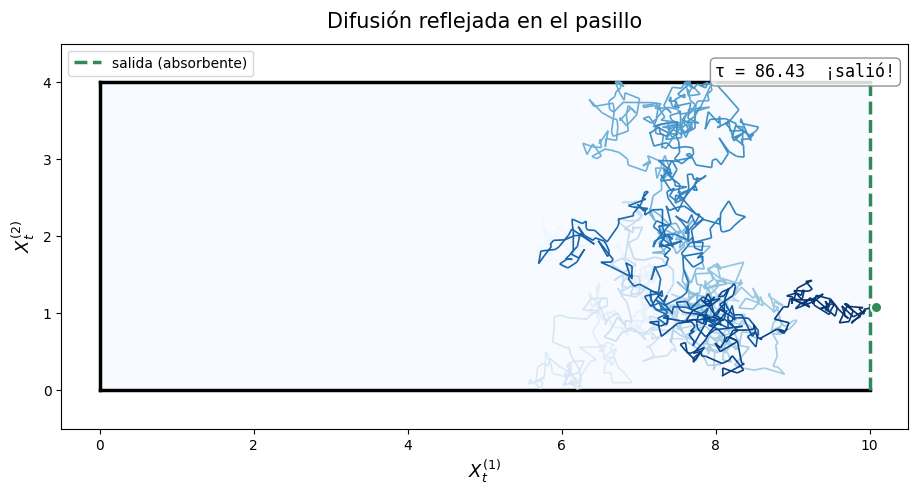

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Rectangle
from matplotlib.collections import LineCollection

# ---------- (tu simulación queda igual hasta el gráfico) ----------
# ... asume X, n_salida, tau, ell, w, dt ya calculados ...

# ---------- Animación ----------
fig, ax = plt.subplots(figsize=(12, 5), dpi=100)
fig.patch.set_facecolor("white")

margen = 0.5
ax.set_xlim(-margen, ell + margen)
ax.set_ylim(-margen, w + margen)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("$X^{(1)}_t$", fontsize=13)
ax.set_ylabel("$X^{(2)}_t$", fontsize=13)
ax.set_title("Difusión reflejada en el pasillo", fontsize=15, pad=12)

# Pasillo: paredes reflectantes sólidas, salida punteada en verde
pasillo = Rectangle((0, 0), ell, w, fill=True, facecolor="aliceblue",
                    alpha=0.5, edgecolor="none", zorder=0)
ax.add_patch(pasillo)
ax.plot([0, ell], [0, 0], color="black", lw=2.5, zorder=1)      # pared inferior
ax.plot([0, ell], [w, w], color="black", lw=2.5, zorder=1)      # pared superior
ax.plot([0, 0], [0, w], color="black", lw=2.5, zorder=1)        # pared izquierda
ax.plot([ell, ell], [0, w], color="seagreen", lw=2.5,
        linestyle="--", zorder=1, label="salida (absorbente)")
ax.legend(loc="upper left", fontsize=10)

trail = LineCollection([], cmap="Blues", lw=1.2, zorder=2)
ax.add_collection(trail)
point, = ax.plot([], [], "o", color="crimson", ms=8,
                 mec="white", mew=1.5, zorder=4)

reloj = ax.text(0.985, 0.95, "", transform=ax.transAxes, fontsize=12,
                va="top", ha="right", family="monospace",
                bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.85))

trail_len = 1500
steps_per_frame = 20
n_frames = int(np.ceil(n_salida / steps_per_frame))
frames_extra = 30           # ~1 s congelado al final mostrando tau

def segmentos(x, y):
    pts = np.array([x, y]).T.reshape(-1, 1, 2)
    return np.concatenate([pts[:-1], pts[1:]], axis=1)

def init():
    trail.set_segments([])
    point.set_data([], [])
    reloj.set_text("")
    return trail, point, reloj

def update(frame):
    idx = min((frame + 1) * steps_per_frame, n_salida)
    i0 = max(0, idx - trail_len)
    segs = segmentos(X[0, i0:idx+1], X[1, i0:idx+1])
    trail.set_segments(segs)
    trail.set_array(np.linspace(0.2, 1.0, max(len(segs), 1)))
    point.set_data([X[0, idx]], [X[1, idx]])
    if idx >= n_salida and tau is not None:
        point.set_color("seagreen")
        reloj.set_text(f"τ = {tau:.2f}  ¡salió!")
    else:
        reloj.set_text(f"t = {idx*dt:7.2f}")
    return trail, point, reloj

ani = animation.FuncAnimation(fig, update, frames=n_frames + frames_extra,
                              init_func=init, blit=True, interval=30)

try:
    ani.save("pasillo.mp4", writer="ffmpeg", fps=30, dpi=150,
             savefig_kwargs={"facecolor": "white"})
except (FileNotFoundError, RuntimeError):
    ani.save("pasillo.gif", writer="pillow", fps=30, dpi=100)